In [1]:
import os
import numpy as np
import healpy as hp
import skyproj
import matplotlib.pyplot as plt

from rubin_nights.plot_utils import PlotStyles
band_colors = PlotStyles.band_colors

In [2]:
from rubin_sim import maf
import scipy.stats as stats

class CountBandYearsMetric(maf.BaseMetric):
    def __init__(
        self,
        night_bins = np.arange(0, 365*10+1, 365),
        night_col="night",
        band_bins = ('u', 'g', 'r', 'i', 'z', 'y', 'all'),
        band_col="band",
        metric_name=None,
        maps=None,
        units="#",
        metric_dtype='object',
        badval=0,
        mask_val=None,
    ):
        super().__init__(col=[night_col, band_col], metric_name=metric_name, maps=maps, units=units, metric_dtype=metric_dtype, badval=badval, mask_val=None)
        self.night_bins = night_bins
        self.night_col = night_col
        self.band_bins = band_bins
        self.band_col = band_col
        self.badval = np.ones(len(self.night_bins) - 1) * self.badval
        self.fill_val = dict([(band, self.badval) for band in self.band_bins])


    def run(self, data_slice, slice_point):
        results = {}        
        for band in self.band_bins:
            if band != "all":
                match = np.where(data_slice[self.band_col] == band)
                ds = data_slice[match]
            else:
                ds = data_slice
            ds.sort(order=self.night_col)
            if len(ds)>0:
                r, bin_edges, bin_number = stats.binned_statistic(ds[self.night_col],
                                                                  ds[self.night_col],
                                                                  bins=self.night_bins,
                                                                  statistic="count",)
                results[band] = r.cumsum()
            else:
                results[band] = self.badval
        return results


def make_year_band_maps(opsdb, nside, fill_value=np.nan):

    run_name = os.path.split(opsdb)[-1].replace('.db', '')
    
    metric = CountBandYearsMetric()
    slicer = maf.HealpixSlicer(nside=64)
    constraint = "scheduler_note not like '%DD%' and scheduler_note not like '%ToO%' and visitExposureTime >= 20"
    bundle = maf.MetricBundle(metric, slicer, constraint=constraint, run_name=run_name)
    g = maf.MetricBundleGroup({'0': bundle}, opsdb, out_dir='tmp', save_early=False)
    g.run_all()
    
    mvals = {}
    for band in metric.band_bins:
        mvals[band] = np.array([v[band] for v in bundle.metric_values.filled(metric.fill_val)])
        mvals[band] = np.where(mvals[band] <= 0,fill_value, mvals[band])

    return mvals

In [3]:
maps = {}

db_path = ['baseline_v5.3.7_10yrs.db']
db_path += ['delay_roll_v5.3.7_10yrs.db']
db_path += ["three_stripes_kr_v5.3.7_10yrs.db"]
db_path += ["desi_stripes_v5.3.7_10yrs.db"]
db_path += ["double_stripes_timing_bands_v5.3.7_10yrs.db"]
db_path += ['fp_mod_9_v5.3.6_10yrs.db']
db_path += ['fp_mod_10_v5.3.6_10yrs.db']

nside = 64
for db in db_path:
    maps[db] = make_year_band_maps(db, nside)

Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes
Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes


In [4]:
def pre_make_year_band_maps(opsdb, nside, fill_value=0):

    run_name = os.path.split(opsdb)[-1].replace('.db', '')
    
    metric = CountBandYearsMetric(night_bins=np.arange(-365, 365*2, 800),)
    slicer = maf.HealpixSlicer(nside=64)
    constraint = "scheduler_note not like '%DD%' and scheduler_note not like '%ToO%' and visitExposureTime >= 20"
    bundle = maf.MetricBundle(metric, slicer, constraint=constraint, run_name=run_name)
    g = maf.MetricBundleGroup({'0': bundle}, opsdb, out_dir='tmp', save_early=False)
    g.run_all()
    
    mvals = {}
    for band in metric.band_bins:
        mvals[band] = np.array([v[band] for v in bundle.metric_values.filled(metric.fill_val)])
        mvals[band] = np.where(mvals[band] <= 0,fill_value, mvals[band])

    return mvals

# This is just https://s3df.slac.stanford.edu/data/rubin/sim-data/prelsst/prelsst_20260922_visits.db 
db_path = ["pre_lsst.db"]
for db in db_path[-1:]:
    maps[db] = pre_make_year_band_maps(db, nside)

Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes


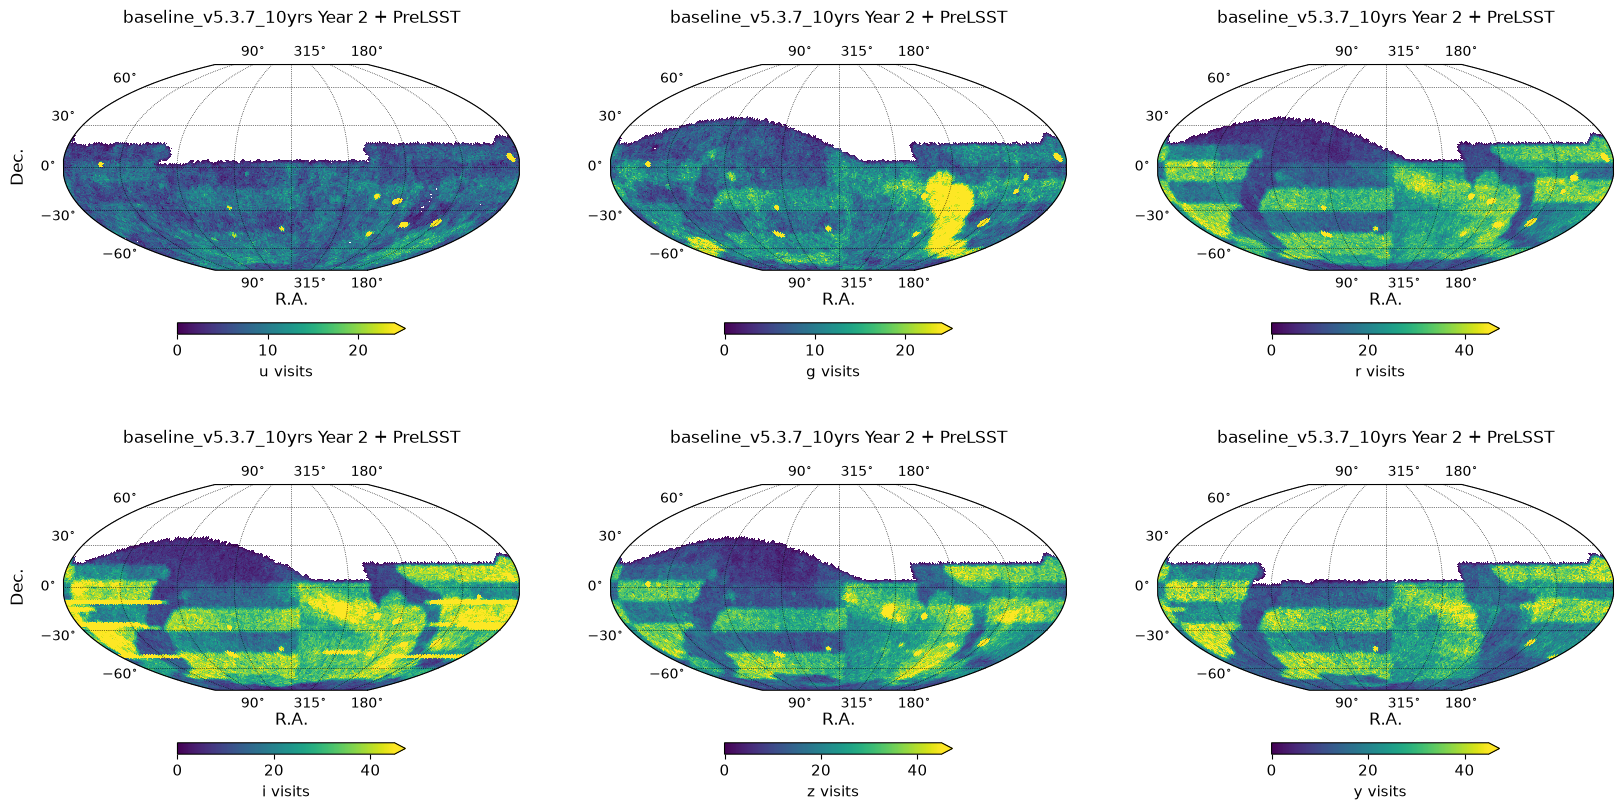

In [9]:
db_path = ['baseline_v5.3.7_10yrs.db']
#db_path = ['three_stripes_kr_v5.3.7_10yrs.db']
#db_path = ["desi_stripes_v5.3.7_10yrs.db"]
#db_path = ["double_stripes_timing_bands_v5.3.7_10yrs.db"]
db = db_path[0]
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(20, 10))
axdict = {"u": ax[0][0], "g": ax[0][1], "r": ax[0][2],
          "i": ax[1][0], "z": ax[1][1], "y": ax[1][2],}
band_ratio = {'u': 0.8, 'g': 0.8, 'r': 1.5, 'i': 1.5, 'z': 1.5, 'y': 1.5}
for year in [1]: #np.arange(0, 10, 1):
    for band in 'ugrizy':
        # Plot the values from this database (above) + preLSST visits
        mval = maps[db][band][:, year] + maps['pre_lsst.db'][band][:, 0]
        sp = skyproj.McBrydeSkyproj(
            ax=axdict[band],
            celestial=True,
            galactic=False,
            gridlines=True,
            n_grid_lon=8,
            n_grid_lat=7,
            lon_0=0,
        )
        mesh, lon_raster, lat_raster, values_raster = sp.draw_hpxmap(mval,
                                                                     cmap='viridis',
                                                                     vmin=0, 
                                                                     vmax=15*(year+1)*band_ratio[band],
                                                                     nest=False,
                                                                     zoom=False,
                                                                     zorder=1.5)
        _ = sp.draw_colorbar(label=f"{band} visits",
                            pad=0.15,
                            shrink=0.5,
                            extend='max',
                            location="bottom",
                            orientation="horizontal",
                        )
        sp.ax.set_xlabel("R.A.", fontsize=12, labelpad=2)
        if band == 'u' or band == 'i':
            sp.ax.set_ylabel("Dec.", fontsize=12, labelpad=10)
        else:
            sp.ax.set_ylabel(None)
        
        #plt.title(f"{db.replace('.db', '')} Year {year+1} only", fontsize="large", pad=30)
        plt.title(f"{db.replace('.db', '')} Year {year+1} + PreLSST", fontsize="large", pad=30)